# Notebook 04 — 1D-CNN Baseline: Training & Evaluation

**Model:** 1D Convolutional Neural Network (3 blocks: 32→64→128 channels, kernel=3, AdaptiveAvgPool)  
**Dataset:** NASA CMAPSS — FD001  

### Why CNN after LSTM?
The CNN serves as a second baseline with a fundamentally different approach to sequence modelling.
Where the LSTM processes cycles sequentially and maintains memory, the CNN detects local patterns
simultaneously across the window. Comparing their results tells us whether temporal order matters
more than local pattern detection for this task.


## 0 · Imports

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import json

from src.utils.config import DATA_PROC, OUT_MODELS, OUT_FIGURES, OUT_RESULTS
from src.models.cnn1d import CNN1DModel
from src.utils.trainer import train, load_splits
from src.evaluation.metrics import all_metrics

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSET = 'FD001'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')

Device  : cpu
PyTorch : 2.12.1+cpu


## 1 · Verify preprocessed data

In [2]:
proc = DATA_PROC / SUBSET
print(f'Checking: {proc}\n')
for name in ['X_train','y_train','X_val','y_val','X_test','y_test']:
    p = proc / f'{name}.npy'
    if p.exists():
        a = np.load(p)
        print(f'  {name:12s}  {str(a.shape):20s}')
    else:
        print(f'  MISSING: {p}')

Checking: C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\data\processed\FD001

  X_train       (15332, 30, 14)     
  y_train       (15332,)            
  X_val         (2399, 30, 14)      
  y_val         (2399,)             
  X_test        (100, 30, 14)       
  y_test        (100,)              


## 2 · Model architecture

In [ ]:
model = CNN1DModel()
print(model)
print(f'\nParameters: {model.count_parameters():,}')
print(f'(LSTM had ~234,625 parameters for comparison)')

# Sanity check forward pass
dummy = torch.randn(4, 30, 14)
with torch.no_grad():
    out = model(dummy)
print(f'\nForward pass: {dummy.shape} → {out.shape} ')

CNN1DModel(
  (conv): Sequential(
    (0): Conv1d(14, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Conv1d(32, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
  )
  (pool): AdaptiveAvgPool1d(output_size=1)
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)

Parameters: 41,057
(LSTM had ~234,625 p

## 3 · Train

CNN trains faster than LSTM because convolutions are parallelisable — no sequential dependency.  


In [5]:
results = train(model_name='cnn1d', subset=SUBSET)
print('\nTraining complete.')


  Model   : CNN1D
  Subset  : FD001
  Device  : cpu
  Parameters : 41,057
  Train batches : 60  |  Val batches : 10
  Ep   1/100  train_mse=7167.1694  val_rmse=72.9517  lr=1.00e-03  [8s]
  Ep   5/100  train_mse=365.4455  val_rmse=22.3181  lr=1.00e-03  [43s]
  Ep  10/100  train_mse=268.0878  val_rmse=22.1783  lr=1.00e-03  [84s]
  Ep  15/100  train_mse=246.3433  val_rmse=22.9713  lr=5.00e-04  [118s]
  Ep  20/100  train_mse=218.9035  val_rmse=19.7361  lr=5.00e-04  [148s]

  Early stopping at epoch 22 (no improvement for 15 epochs)

  ── Test Results (CNN1D, FD001) ──
RMSE=19.506  MAE=15.350  R²=0.7631  NASA=995.0
  Best val RMSE : 18.9745
  Total time    : 162s
  Results saved  → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\results\cnn1d_FD001_results.json
  Checkpoint     → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\models\cnn1d_FD001_best.pt

Training complete.


## 4 · Training curves

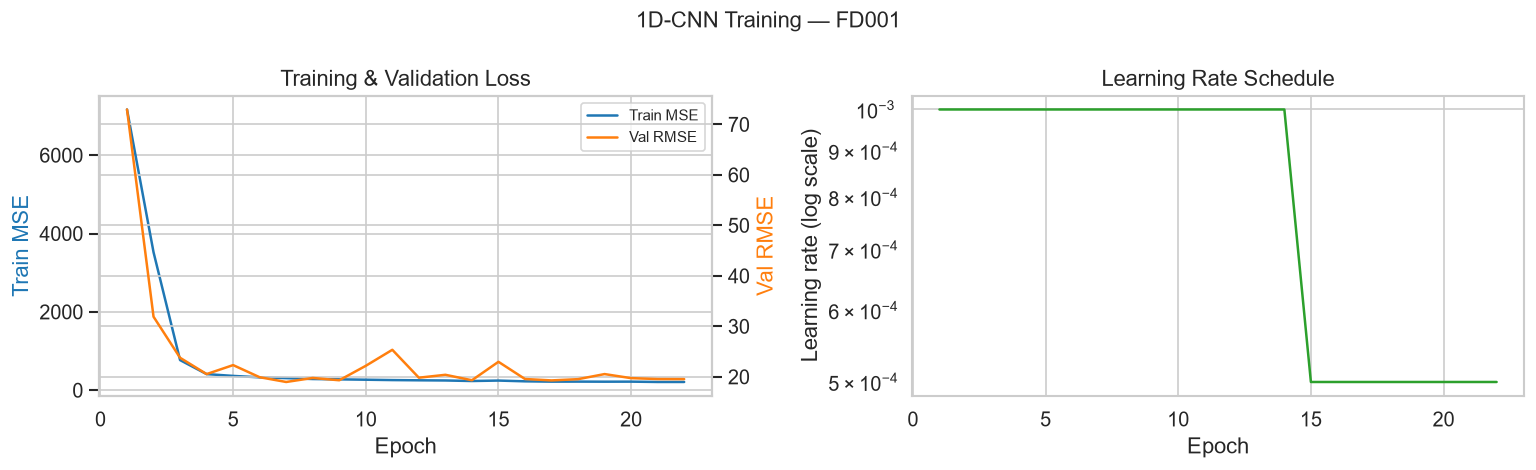

Best val RMSE: 18.9745
Epochs run   : 22


In [6]:
log       = results['log']
epochs    = [r['epoch']     for r in log]
train_mse = [r['train_mse'] for r in log]
val_rmse  = [r['val_rmse']  for r in log]
lrs       = [r['lr']        for r in log]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

ax  = axes[0]
ax2 = ax.twinx()
ax.plot(epochs, train_mse, color='#1f77b4', lw=1.5, label='Train MSE')
ax2.plot(epochs, val_rmse, color='#ff7f0e', lw=1.5, label='Val RMSE')
ax.set_xlabel('Epoch')
ax.set_ylabel('Train MSE', color='#1f77b4')
ax2.set_ylabel('Val RMSE', color='#ff7f0e')
ax.set_title('Training & Validation Loss')
l1, lb1 = ax.get_legend_handles_labels()
l2, lb2 = ax2.get_legend_handles_labels()
ax.legend(l1+l2, lb1+lb2, fontsize=9)

axes[1].semilogy(epochs, lrs, color='#2ca02c', lw=1.5)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Learning rate (log scale)')
axes[1].set_title('Learning Rate Schedule')

fig.suptitle(f'1D-CNN Training — {SUBSET}', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'cnn_{SUBSET}_training_curves.png', bbox_inches='tight')
plt.show()
print(f'Best val RMSE: {results["best_val_rmse"]:.4f}')
print(f'Epochs run   : {results["epochs_run"]}')

## 5 · Test metrics

In [7]:
m = results['test']
print(f'\n{" Test Results — 1D-CNN, " + SUBSET + " ":=^50}')
print(f'  RMSE       : {m["RMSE"]:.3f}  cycles')
print(f'  MAE        : {m["MAE"]:.3f}  cycles')
print(f'  R²         : {m["R2"]:.4f}')
print(f'  NASA Score : {m["NASA_Score"]:.1f}  (lower = better)')
print('='*50)


========== Test Results — 1D-CNN, FD001 ==========
  RMSE       : 19.506  cycles
  MAE        : 15.350  cycles
  R²         : 0.7631
  NASA Score : 995.0  (lower = better)


## 6 · Predicted vs actual RUL

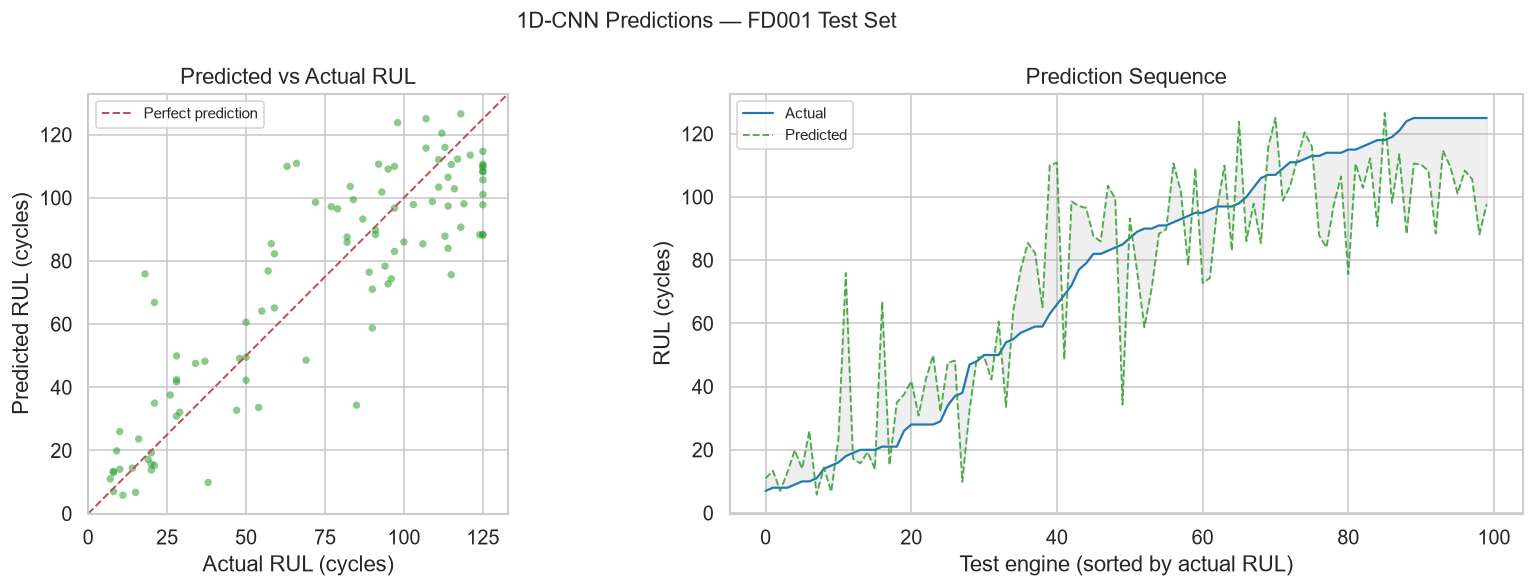

In [9]:
_, _, te_loader, y_test = load_splits(SUBSET, DEVICE)

best_model = CNN1DModel().to(DEVICE)
best_model.load_state_dict(
    torch.load(OUT_MODELS / f'cnn1d_{SUBSET}_best.pt',
               map_location=DEVICE, weights_only=True)
)
best_model.eval()

preds = []
with torch.no_grad():
    for X_b, _ in te_loader:
        preds.append(best_model(X_b.to(DEVICE)).cpu().numpy())
preds = np.concatenate(preds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.scatter(y_test, preds, alpha=0.55, s=20, color='#2ca02c', edgecolors='none')
lim = [0, max(y_test.max(), preds.max()) * 1.05]
ax.plot(lim, lim, 'r--', lw=1.2, label='Perfect prediction')
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel('Actual RUL (cycles)')
ax.set_ylabel('Predicted RUL (cycles)')
ax.set_title('Predicted vs Actual RUL')
ax.legend(fontsize=9); ax.set_aspect('equal')

idx = np.argsort(y_test)
axes[1].plot(y_test[idx], label='Actual',    color='#1f77b4', lw=1.3)
axes[1].plot(preds[idx],  label='Predicted', color='#2ca02c', lw=1.1, ls='--', alpha=0.85)
axes[1].fill_between(range(len(y_test)), y_test[idx], preds[idx],
                     alpha=0.12, color='grey')
axes[1].set_xlabel('Test engine (sorted by actual RUL)')
axes[1].set_ylabel('RUL (cycles)')
axes[1].set_title('Prediction Sequence')
axes[1].legend(fontsize=9)

fig.suptitle(f'1D-CNN Predictions — {SUBSET} Test Set', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'cnn_{SUBSET}_predictions.png', bbox_inches='tight')
plt.show()

## 7 · Error analysis

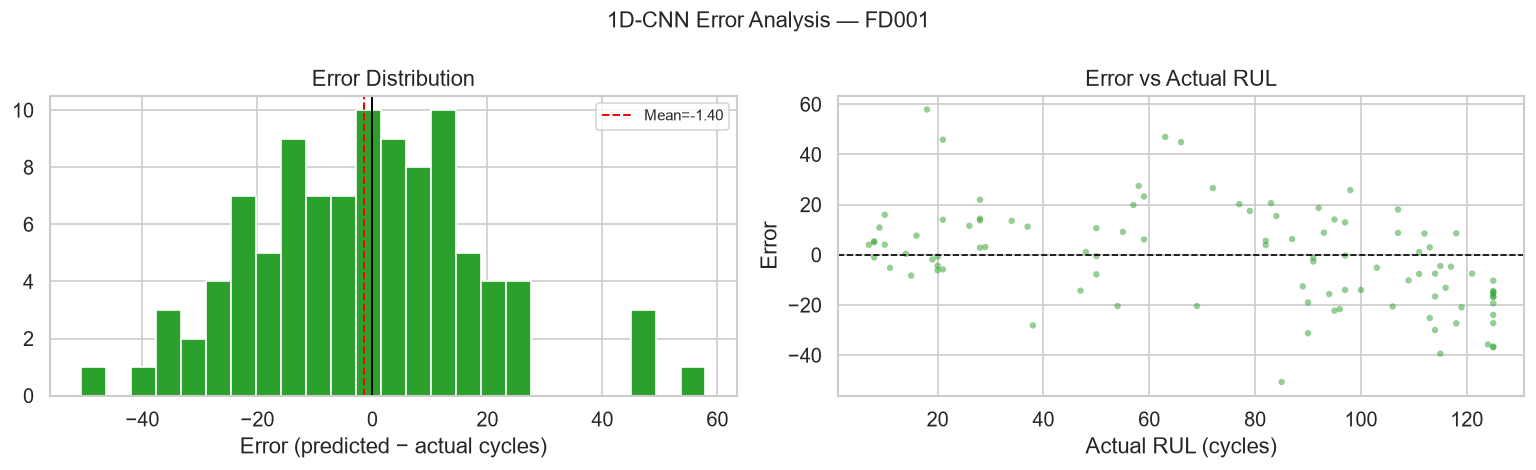

Mean error (bias)   : -1.401 cycles
Within ±10 cycles   : 39.0%
Within ±20 cycles   : 71.0%
Early predictions   : 47.0%  (risky)
Late predictions    : 53.0%  (conservative)


In [10]:
errors = preds - y_test

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(errors, bins=25, color='#2ca02c', edgecolor='white')
axes[0].axvline(0, color='black', lw=1.2)
axes[0].axvline(errors.mean(), color='red', lw=1.2, ls='--',
                label=f'Mean={errors.mean():.2f}')
axes[0].set_xlabel('Error (predicted − actual cycles)')
axes[0].set_title('Error Distribution')
axes[0].legend(fontsize=9)

axes[1].scatter(y_test, errors, alpha=0.5, s=15, color='#2ca02c', edgecolors='none')
axes[1].axhline(0, color='black', ls='--', lw=1)
axes[1].set_xlabel('Actual RUL (cycles)')
axes[1].set_ylabel('Error')
axes[1].set_title('Error vs Actual RUL')

fig.suptitle(f'1D-CNN Error Analysis — {SUBSET}', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'cnn_{SUBSET}_errors.png', bbox_inches='tight')
plt.show()

print(f'Mean error (bias)   : {errors.mean():.3f} cycles')
print(f'Within ±10 cycles   : {(np.abs(errors)<=10).mean()*100:.1f}%')
print(f'Within ±20 cycles   : {(np.abs(errors)<=20).mean()*100:.1f}%')
print(f'Early predictions   : {(errors>0).mean()*100:.1f}%  (risky)')
print(f'Late predictions    : {(errors<0).mean()*100:.1f}%  (conservative)')

## 8 · LSTM vs CNN comparison

In [12]:
# Load LSTM results from saved JSON
lstm_path = OUT_RESULTS / f'lstm_{SUBSET}_results.json'
cnn_path  = OUT_RESULTS / f'cnn1d_{SUBSET}_results.json'

if lstm_path.exists() and cnn_path.exists():
    lstm_m = json.load(open(lstm_path))['test']
    cnn_m  = json.load(open(cnn_path))['test']

    print(f'\n{" Model Comparison — FD001 ":=^55}')
    print(f'{"Metric":<15} {"LSTM":>12} {"1D-CNN":>12} {"Better":>10}')
    print('-' * 55)
    for metric in ['RMSE', 'MAE', 'R2', 'NASA_Score']:
        lstm_v = lstm_m[metric]
        cnn_v  = cnn_m[metric]
        if metric == 'R2':
            better = 'CNN' if cnn_v > lstm_v else 'LSTM'
        else:
            better = 'CNN' if cnn_v < lstm_v else 'LSTM'
        print(f'  {metric:<13} {lstm_v:>12.3f} {cnn_v:>12.3f} {better:>10}')
    print('=' * 55)
else:
    print('LSTM results not found — run notebook 03 first.')
    m = results['test']
    print(f'CNN: RMSE={m["RMSE"]:.3f}  MAE={m["MAE"]:.3f}  R2={m["R2"]:.4f}  NASA={m["NASA_Score"]:.1f}')


============== Model Comparison — FD001 ===============
Metric                  LSTM       1D-CNN     Better
-------------------------------------------------------
  RMSE                12.876       19.506       LSTM
  MAE                  9.824       15.350       LSTM
  R2                   0.897        0.763       LSTM
  NASA_Score         232.805      994.981       LSTM


In [18]:
m = results['test']
print(f"""

   1D-CNN BASELINE — {SUBSET} RESULTS                    

   RMSE       : {m['RMSE']:>8.3f} cycles                 
   MAE        : {m['MAE']:>8.3f} cycles                  
   R²         : {m['R2']:>8.4f}                          
   NASA Score : {m['NASA_Score']:>10.1f}                 

   PUBLISHED FD001 RMSE BASELINES                        
   LSTM  (Zheng et al., 2017)       : ~16.1              
   CNN   (Babu et al., 2016)        : ~18.5              
   Transformer (Fan et al., 2020)   : ~13.2                              

""")



   1D-CNN BASELINE — FD001 RESULTS                    

   RMSE       :   19.506 cycles                 
   MAE        :   15.350 cycles                  
   R²         :   0.7631                          
   NASA Score :      995.0                 

   PUBLISHED FD001 RMSE BASELINES                        
   LSTM  (Zheng et al., 2017)       : ~16.1              
   CNN   (Babu et al., 2016)        : ~18.5              
   Transformer (Fan et al., 2020)   : ~13.2                              


